# Game Player Churn Prediction and Retention Insights

## Business Problem
Identify players at risk of becoming inactive so a gaming team can prioritise retention research and experiments.

## Prediction Task
Use recorded activity of each player for first 30 days to predict whether they have no gameplay during the following 7 days.

## Approach
- Audit and prepare gameplay and purchase records.
- Create player-level behavioural features.
- Compare a dummy baseline, logistic regression and XGBoost.
- Select classification thresholds using validation data.
- Evaluate once on held-out test players.
- Explain XGBoost predictions with SHAP.
- Measure performance when prioritising the highest-risk 20% of players.

## Dataset
Game Difficulty for Difficulty-Aware Framework(DAF): Anonymised activity from a mobile puzzle game.
Source: [Original dataset : Tsinghua University cloud storage](https://cloud.tsinghua.edu.cn/d/3a13277acd6b4daab1f3/)

## Install Packages

In [2]:
%pip install -q pandas numpy matplotlib seaborn scikit-learn xgboost shap joblib


[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


## Import Libraries

In [3]:
from pathlib import Path
from importlib.metadata import version
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import shap
import joblib

from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    precision_recall_curve,
    classification_report,
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    PrecisionRecallDisplay,
)
from xgboost import XGBClassifier

SEED = 42
np.random.seed(SEED)

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)

for package in ["pandas", "numpy", "scikit-learn", "xgboost", "shap"]:
    print(f"{package}: {version(package)}")

pandas: 2.3.3
numpy: 2.4.6
scikit-learn: 1.7.2
xgboost: 3.1.2
shap: 0.52.0


## Locate the Files

In [5]:
DATA_DIR = Path("/Users/adityaraj/Desktop/Churn")

INTERACTIONS_PATH = DATA_DIR / "interactions.csv"
PAYMENTS_PATH = DATA_DIR / "payment.csv"

for path in [INTERACTIONS_PATH, PAYMENTS_PATH]:
    print(f"{path.name}: {'Found' if path.is_file() else 'Not found'}")

    if not path.is_file():
        raise FileNotFoundError(f"Cannot find: {path}")

print("Both data files found.")

interactions.csv: Found
payment.csv: Found
Both data files found.


## Load the CSV Files

In [34]:
INTERACTION_COLUMNS = [
    "user_id", "session_id", "level_id", "win", "duration",
    "energy", "retry_time", "timestamp", "item_all", "session_depth", "time",
]

PAYMENT_COLUMNS = [
    "gold_amount", "coin_amount", "level", "timestamp", "user_id",
]

def read_game_csv(path, expected_columns):
    header = pd.read_csv(path, nrows=0)
    names = [
        str(c).strip().lower().lstrip("\ufeff")
        for c in header.columns
    ]

    if set(expected_columns).issubset(names):
        frame = pd.read_csv(path, low_memory=False)
        frame.columns = names
        frame = frame[expected_columns].copy()
    else:
        frame = pd.read_csv(path, header=None, low_memory=False)

        if frame.shape[1] != len(expected_columns):
            raise ValueError(
                f"{path.name}: expected {len(expected_columns)} columns, "
                f"found {frame.shape[1]}. Inspect the file before continuing."
            )

        frame.columns = expected_columns

    return frame

interactions = read_game_csv(
    INTERACTIONS_PATH, INTERACTION_COLUMNS
)
payments = read_game_csv(
    PAYMENTS_PATH, PAYMENT_COLUMNS
)

print("Gameplay records:", interactions.shape)
print("Purchase records:", payments.shape)

display(interactions.head())
display(payments.head())

Gameplay records: (4517349, 11)
Purchase records: (24447, 5)


,user_id,session_id,level_id,win,duration,energy,retry_time,timestamp,item_all,session_depth,time
0,1,1,11,1,95.0,25.0,0,1.577887e+09,0.0,0,2020-01-01 21:54:44
1,1,1,13,0,81.0,25.0,0,1.577887e+09,0.0,1,2020-01-01 21:56:35
2,1,1,13,0,93.0,20.0,1,1.577887e+09,1.0,2,2020-01-01 21:58:11
3,1,1,13,1,94.0,20.0,2,1.577887e+09,2.0,3,2020-01-01 21:59:47
4,1,1,16,1,126.0,20.0,0,1.577887e+09,0.0,4,2020-01-01 22:02:05


,gold_amount,coin_amount,level,timestamp,user_id
0,0,20,224,1.579608e+09,2
1,60,60,238,1.579845e+09,2
2,60,60,241,1.579849e+09,2
3,60,60,245,1.579888e+09,2
4,60,60,9184,1.578134e+09,4


## Inspect Data Quality

In [33]:
def audit_table(frame, name):
    print(f"\n{name}")
    print("Rows:", len(frame))
    print("Exact duplicate rows:", frame.duplicated().sum())

    display(pd.DataFrame({
        "dtype": frame.dtypes.astype(str),
        "missing": frame.isna().sum(),
        "missing_percent": frame.isna().mean().mul(100).round(2),
        "unique_values": frame.nunique(),
    }))

audit_table(interactions, "Gameplay")
audit_table(payments, "Purchases")


Gameplay
Rows: 4517349
Exact duplicate rows: 0


,dtype,missing,missing_percent,unique_values
user_id,int64,0,0.0,4089
session_id,int64,0,0.0,480
level_id,int64,0,0.0,6510
win,int64,0,0.0,2
duration,float64,0,0.0,601
energy,float64,0,0.0,27
retry_time,int64,0,0.0,192
timestamp,float64,0,0.0,2506930
item_all,float64,0,0.0,37
session_depth,int64,0,0.0,550



Purchases
Rows: 24447
Exact duplicate rows: 124


,dtype,missing,missing_percent,unique_values
gold_amount,int64,0,0.0,11
coin_amount,int64,0,0.0,24
level,int64,0,0.0,1321
timestamp,float64,0,0.0,24240
user_id,int64,0,0.0,3488


## Validate Identifiers and Numeric Fields

In [8]:
for frame in [interactions, payments]:
    if frame["user_id"].isna().any():
        raise ValueError("Missing user IDs require investigation.")

    # Normalise numeric-looking IDs such as 123.0 to 123.
    frame["user_id"] = (
        frame["user_id"]
        .astype("string")
        .str.strip()
        .str.replace(r"^(\d+)\.0$", r"\1", regex=True)
    )

if interactions["session_id"].isna().any():
    raise ValueError("Missing session IDs require investigation.")

interactions["session_id"] = (
    interactions["session_id"].astype("string")
)

game_numeric = [
    "level_id", "win", "duration", "retry_time", "session_depth"
]

payment_numeric = ["gold_amount", "coin_amount", "level"]

for frame, columns in [
    (interactions, game_numeric),
    (payments, payment_numeric),
]:
    for column in columns:
        original = frame[column]
        converted = pd.to_numeric(original, errors="coerce")

        invalid = original.notna() & converted.isna()
        if invalid.any():
            raise ValueError(
                f"Unexpected non-numeric values in {column}: "
                f"{original[invalid].head().tolist()}"
            )

        frame[column] = converted.replace(
            [np.inf, -np.inf], np.nan
        )

if not set(interactions["win"].dropna().unique()).issubset({0, 1}):
    raise ValueError("Expected win to be encoded as 0 and 1.")

for column in ["duration", "retry_time", "session_depth"]:
    if interactions[column].dropna().lt(0).any():
        raise ValueError(f"Negative values found in {column}.")

print("Basic type and value checks passed.")

Basic type and value checks passed.


## Parse Timestamps

In [9]:
def parse_event_time(series):
    if series.isna().any():
        raise ValueError("Missing timestamps require investigation.")

    numeric = pd.to_numeric(series, errors="coerce")

    if numeric.notna().all():
        magnitude = numeric.abs().median()

        if 1e8 <= magnitude < 1e11:
            unit = "s"
        elif 1e11 <= magnitude < 1e14:
            unit = "ms"
        elif 1e14 <= magnitude < 1e17:
            unit = "us"
        elif 1e17 <= magnitude < 1e20:
            unit = "ns"
        else:
            raise ValueError(
                "Unrecognised numeric timestamp format. "
                f"Sample: {series.head().tolist()}"
            )

        parsed = pd.to_datetime(
            numeric, unit=unit, utc=True, errors="coerce"
        )
    else:
        parsed = pd.to_datetime(
            series.astype(str),
            format="mixed",
            utc=True,
            errors="coerce",
        )

    if parsed.isna().any():
        raise ValueError("Some timestamps could not be parsed.")

    if not parsed.dt.year.between(2000, 2035).all():
        raise ValueError("Unexpected dates; check timestamp units.")

    return parsed


interactions["event_time"] = parse_event_time(
    interactions["timestamp"]
)
payments["event_time"] = parse_event_time(
    payments["timestamp"]
)

print(
    "Gameplay range:",
    interactions["event_time"].min(),
    "to",
    interactions["event_time"].max(),
)

print(
    "Purchase range:",
    payments["event_time"].min(),
    "to",
    payments["event_time"].max(),
)

display(
    interactions[["timestamp", "event_time"]].head()
)

Gameplay range: 2019-12-31 20:00:30+00:00 to 2020-02-22 19:59:54+00:00
Purchase range: 2019-12-31 17:12:35+00:00 to 2020-03-02 15:53:46+00:00


,timestamp,event_time
0,1.577887e+09,2020-01-01 13:54:44+00:00
1,1.577887e+09,2020-01-01 13:56:35+00:00
2,1.577887e+09,2020-01-01 13:58:11+00:00
3,1.577887e+09,2020-01-01 13:59:47+00:00
4,1.577887e+09,2020-01-01 14:02:05+00:00


## Define Observation and Prediction Windows

In [10]:
OBSERVATION_DAYS = 30
PREDICTION_DAYS = 7

DATA_END = interactions["event_time"].max()

players = (
    interactions.groupby("user_id")
    .agg(first_seen=("event_time", "min"))
)

players["prediction_time"] = (
    players["first_seen"]
    + pd.Timedelta(days=OBSERVATION_DAYS)
)

players["outcome_end"] = (
    players["prediction_time"]
    + pd.Timedelta(days=PREDICTION_DAYS)
)

eligible = players.loc[
    players["outcome_end"] <= DATA_END
].copy()

if len(eligible) < 100:
    raise ValueError(
        "Fewer than 100 eligible players. Check dates and data coverage."
    )

print("All players:", len(players))
print("Eligible players:", len(eligible))
print("Excluded for incomplete follow-up:", len(players) - len(eligible))

All players: 4089
Eligible players: 4010
Excluded for incomplete follow-up: 79


## Separate Historical Activity from Future Outcomes

In [11]:
events = interactions.merge(
    eligible,
    left_on="user_id",
    right_index=True,
    how="inner",
    validate="many_to_one",
)

history = events.loc[
    (events["event_time"] >= events["first_seen"])
    & (events["event_time"] < events["prediction_time"])
].copy()

future = events.loc[
    (events["event_time"] >= events["prediction_time"])
    & (events["event_time"] < events["outcome_end"])
].copy()

returned_players = future["user_id"].unique()

labels = pd.Series(
    (~eligible.index.isin(returned_players)).astype(int),
    index=eligible.index,
    name="churn",
)

assert (history["event_time"] < history["prediction_time"]).all()

print("Historical gameplay records:", len(history))
print("Future gameplay records:", len(future))
print("Churn label: 1 = no gameplay in the following 7 days")
display(labels.value_counts().rename_axis("churn").to_frame("players"))

Historical gameplay records: 3355730
Future gameplay records: 508106
Churn label: 1 = no gameplay in the following 7 days


,players
churn,
1,2212
0,1798


## Create Gameplay Features

In [12]:
history["relative_day"] = (
    (history["event_time"] - history["first_seen"])
    .dt.total_seconds()
    .floordiv(86400)
    .astype(int)
)

grouped = history.groupby("user_id")

features = grouped.agg(
    total_plays=("level_id", "size"),
    total_sessions=("session_id", "nunique"),
    active_days=("relative_day", "nunique"),
    unique_levels=("level_id", "nunique"),
    max_level=("level_id", "max"),
    win_rate=("win", "mean"),
    mean_duration_raw=("duration", "mean"),
    mean_retries=("retry_time", "mean"),
    mean_session_depth=("session_depth", "mean"),
)

features["total_duration_raw"] = grouped["duration"].sum(
    min_count=1
)

last_play = grouped["event_time"].max()

features["days_since_last_play"] = (
    eligible.loc[features.index, "prediction_time"] - last_play
).dt.total_seconds() / 86400

features["plays_per_session"] = (
    features["total_plays"] / features["total_sessions"]
)

recent_start = (
    history["prediction_time"] - pd.Timedelta(days=7)
)
previous_start = (
    history["prediction_time"] - pd.Timedelta(days=14)
)

recent = history.loc[history["event_time"] >= recent_start]
previous = history.loc[
    (history["event_time"] >= previous_start)
    & (history["event_time"] < recent_start)
]

features["plays_last_7d"] = (
    recent.groupby("user_id").size()
    .reindex(features.index, fill_value=0)
)

features["plays_previous_7d"] = (
    previous.groupby("user_id").size()
    .reindex(features.index, fill_value=0)
)

features["active_days_last_7d"] = (
    recent.groupby("user_id")["relative_day"].nunique()
    .reindex(features.index, fill_value=0)
)

features["play_count_change_7d"] = (
    features["plays_last_7d"] - features["plays_previous_7d"]
)

display(features.head())

,total_plays,total_sessions,active_days,unique_levels,max_level,win_rate,mean_duration_raw,mean_retries,mean_session_depth,total_duration_raw,days_since_last_play,plays_per_session,plays_last_7d,plays_previous_7d,active_days_last_7d,play_count_change_7d
user_id,,,,,,,,,,,,,,,,
1,488,37,27,168,254,0.325820,133.956967,2.026639,10.038934,65371.0,1.257986,13.189189,57,50,5,7
10,100,15,8,63,124,0.610000,153.840000,0.340000,4.410000,15384.0,22.086100,6.666667,0,0,0,0
100,421,46,20,153,236,0.349169,100.173397,2.149644,24.726841,42173.0,4.892176,9.152174,1,4,1,-3
1000,1111,116,27,218,290,0.192619,154.639964,3.307831,10.514851,171805.0,0.333287,9.577586,246,289,7,-43
1001,2179,113,29,403,505,0.178063,95.685177,4.579165,27.442864,208498.0,0.058681,19.283186,732,480,7,252


## Create Purchase Features

In [13]:
purchase_events = payments.merge(
    eligible,
    left_on="user_id",
    right_index=True,
    how="inner",
    validate="many_to_one",
)

purchase_history = purchase_events.loc[
    (purchase_events["event_time"] >= purchase_events["first_seen"])
    & (
        purchase_events["event_time"]
        < purchase_events["prediction_time"]
    )
].copy()

purchase_grouped = purchase_history.groupby("user_id")

purchase_features = purchase_grouped.agg(
    purchase_count=("event_time", "size"),
)

purchase_features["gold_total_scaled"] = (
    purchase_grouped["gold_amount"].sum(min_count=1)
)

purchase_features["coin_total_scaled"] = (
    purchase_grouped["coin_amount"].sum(min_count=1)
)

features = features.join(purchase_features, how="left")

no_purchases = features["purchase_count"].isna()

features.loc[
    no_purchases,
    ["purchase_count", "gold_total_scaled", "coin_total_scaled"]
] = 0

features["is_payer"] = (
    features["purchase_count"] > 0
).astype(int)

display(features.head())

,total_plays,total_sessions,active_days,unique_levels,max_level,win_rate,mean_duration_raw,mean_retries,mean_session_depth,total_duration_raw,days_since_last_play,plays_per_session,plays_last_7d,plays_previous_7d,active_days_last_7d,play_count_change_7d,purchase_count,gold_total_scaled,coin_total_scaled,is_payer
user_id,,,,,,,,,,,,,,,,,,,,
1,488,37,27,168,254,0.325820,133.956967,2.026639,10.038934,65371.0,1.257986,13.189189,57,50,5,7,0.0,0.0,0.0,0
10,100,15,8,63,124,0.610000,153.840000,0.340000,4.410000,15384.0,22.086100,6.666667,0,0,0,0,1.0,0.0,80.0,1
100,421,46,20,153,236,0.349169,100.173397,2.149644,24.726841,42173.0,4.892176,9.152174,1,4,1,-3,0.0,0.0,0.0,0
1000,1111,116,27,218,290,0.192619,154.639964,3.307831,10.514851,171805.0,0.333287,9.577586,246,289,7,-43,0.0,0.0,0.0,0
1001,2179,113,29,403,505,0.178063,95.685177,4.579165,27.442864,208498.0,0.058681,19.283186,732,480,7,252,0.0,0.0,0.0,0


## Finalise the Modelling Table

In [14]:
model_data = features.join(labels, how="inner")

before_filter = len(model_data)

model_data = model_data.loc[
    model_data["plays_last_7d"] > 0
].copy()

model_data = model_data.replace([np.inf, -np.inf], np.nan)

assert model_data.index.is_unique
assert model_data["churn"].notna().all()

class_counts = model_data["churn"].value_counts()

if len(class_counts) != 2 or class_counts.min() < 20:
    raise ValueError(
        "Insufficient examples in one class. Inspect the cohort "
        "and churn definition before fitting models."
    )

print("Eligible players:", before_filter)
print("Recently active players used:", len(model_data))
print("Churn rate:", f"{model_data['churn'].mean():.1%}")

display(class_counts.rename_axis("churn").to_frame("players"))

Eligible players: 4010
Recently active players used: 2124
Churn rate: 15.3%


,players
churn,
0,1798
1,326


## Split into Training, Validation and Test Players

In [15]:
X = model_data.drop(columns="churn")
y = model_data["churn"].astype(int)

X_development, X_test, y_development, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=SEED,
)

X_train, X_valid, y_train, y_valid = train_test_split(
    X_development,
    y_development,
    test_size=0.25,
    stratify=y_development,
    random_state=SEED,
)

assert set(X_train.index).isdisjoint(X_valid.index)
assert set(X_train.index).isdisjoint(X_test.index)
assert set(X_valid.index).isdisjoint(X_test.index)

display(pd.DataFrame({
    "split": ["train", "validation", "test"],
    "players": [len(y_train), len(y_valid), len(y_test)],
    "churn_rate": [y_train.mean(), y_valid.mean(), y_test.mean()],
}))

,split,players,churn_rate
0,train,1274,0.153846
1,validation,425,0.152941
2,test,425,0.152941


## Explore Training Data

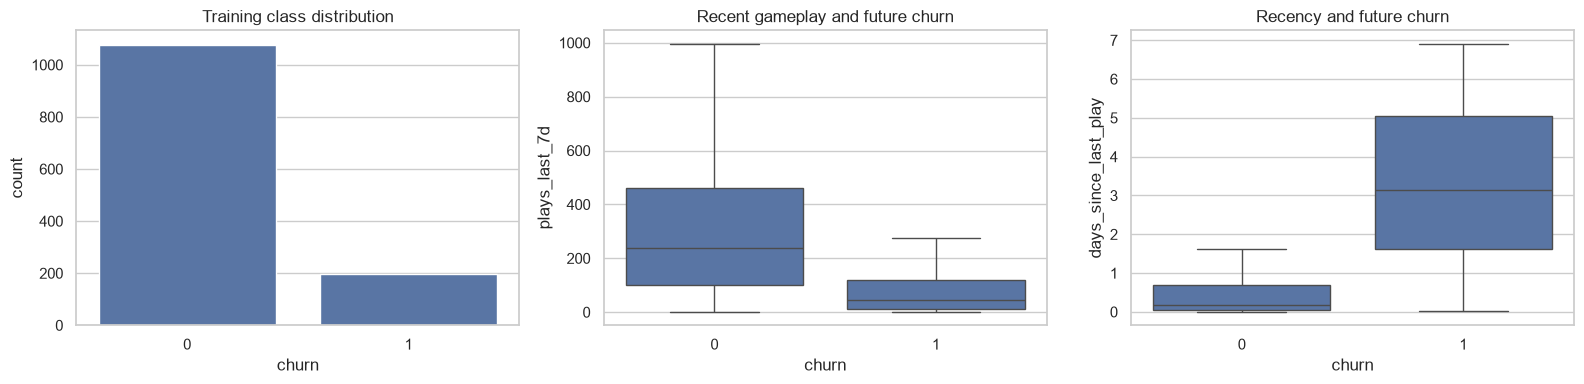

,count,mean,std,min,25%,50%,75%,max
total_plays,1274.0,1249.168760,924.982316,73.000000,565.250000,984.000000,1664.750000,5694.000000
total_sessions,1274.0,83.488226,47.176744,10.000000,48.000000,73.000000,109.000000,308.000000
active_days,1274.0,24.978807,4.562598,7.000000,22.000000,26.000000,29.000000,30.000000
unique_levels,1274.0,249.263736,129.368153,31.000000,155.000000,211.500000,307.000000,704.000000
max_level,1274.0,445.365777,811.876379,75.000000,235.000000,300.500000,414.000000,7872.000000
win_rate,1274.0,0.244930,0.111828,0.063154,0.168493,0.217289,0.291896,0.946759
mean_duration_raw,1274.0,105.181119,21.439251,47.130067,90.847823,102.414122,116.936680,240.334483
mean_retries,1274.0,3.575463,2.135276,0.055556,2.035150,3.226487,4.665625,16.197101
mean_session_depth,1274.0,18.139318,11.924602,1.791946,9.484045,15.379968,23.507236,111.724977
total_duration_raw,1274.0,124709.748038,87022.214632,9844.000000,61578.250000,101215.000000,165967.000000,556910.000000


In [16]:
train_analysis = X_train.join(y_train)

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

sns.countplot(
    data=train_analysis, x="churn", ax=axes[0]
)
axes[0].set_title("Training class distribution")

sns.boxplot(
    data=train_analysis,
    x="churn",
    y="plays_last_7d",
    showfliers=False,
    ax=axes[1],
)
axes[1].set_title("Recent gameplay and future churn")

sns.boxplot(
    data=train_analysis,
    x="churn",
    y="days_since_last_play",
    showfliers=False,
    ax=axes[2],
)
axes[2].set_title("Recency and future churn")

plt.tight_layout()
plt.show()

display(X_train.describe().T)

## Fit the Baseline Models

In [17]:
dummy_model = DummyClassifier(strategy="prior")

logistic_model = Pipeline([
    (
        "imputer",
        SimpleImputer(strategy="median", keep_empty_features=True),
    ),
    ("scaler", StandardScaler()),
    (
        "classifier",
        LogisticRegression(max_iter=3000, random_state=SEED),
    ),
])

dummy_model.fit(X_train, y_train)
logistic_model.fit(X_train, y_train)

print("Baseline models trained.")

Baseline models trained.


## Prepare XGBoost Inputs

In [18]:
xgb_imputer = SimpleImputer(
    strategy="median",
    keep_empty_features=True,
)

def imputed_frame(values, original):
    return pd.DataFrame(
        values,
        columns=original.columns,
        index=original.index,
    )

X_train_xgb = imputed_frame(
    xgb_imputer.fit_transform(X_train), X_train
)

X_valid_xgb = imputed_frame(
    xgb_imputer.transform(X_valid), X_valid
)

## Train and Select XGBoost

In [19]:
configurations = [
    {"max_depth": 2, "n_estimators": 200},
    {"max_depth": 3, "n_estimators": 300},
    {"max_depth": 4, "n_estimators": 300},
]

candidate_models = []
candidate_results = []

for config in configurations:
    model = XGBClassifier(
        objective="binary:logistic",
        eval_metric="logloss",
        tree_method="hist",
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        min_child_weight=5,
        reg_lambda=5.0,
        random_state=SEED,
        n_jobs=2,
        **config,
    )

    model.fit(X_train_xgb, y_train)

    probability = model.predict_proba(X_valid_xgb)[:, 1]
    score = average_precision_score(y_valid, probability)

    candidate_models.append(model)
    candidate_results.append({
        **config,
        "validation_average_precision": score,
    })

candidate_results = pd.DataFrame(candidate_results)

best_position = int(
    candidate_results["validation_average_precision"].argmax()
)

xgb_model = candidate_models[best_position]

display(
    candidate_results.sort_values(
        "validation_average_precision", ascending=False
    )
)

,max_depth,n_estimators,validation_average_precision
0,2,200,0.871689
1,3,300,0.844150
2,4,300,0.827768


## Compare Validation Performance

In [20]:
validation_probabilities = {
    "Dummy": dummy_model.predict_proba(X_valid)[:, 1],
    "Logistic regression": logistic_model.predict_proba(X_valid)[:, 1],
    "XGBoost": xgb_model.predict_proba(X_valid_xgb)[:, 1],
}

validation_results = pd.DataFrame([
    {
        "model": name,
        "average_precision": average_precision_score(y_valid, probability),
        "roc_auc": roc_auc_score(y_valid, probability),
    }
    for name, probability in validation_probabilities.items()
]).sort_values("average_precision", ascending=False)

display(validation_results.round(4))

,model,average_precision,roc_auc
1,Logistic regression,0.8896,0.9629
2,XGBoost,0.8717,0.9574
0,Dummy,0.1529,0.5000


## Select Thresholds using Validation Data

In [21]:
def select_f1_threshold(actual, probability):
    precision, recall, thresholds = precision_recall_curve(
        actual, probability
    )

    f1_values = (
        2 * precision[:-1] * recall[:-1]
        / np.maximum(precision[:-1] + recall[:-1], 1e-12)
    )

    best_index = int(np.argmax(f1_values))
    return float(thresholds[best_index])


thresholds = {"Dummy": 0.5}

for name in ["Logistic regression", "XGBoost"]:
    thresholds[name] = select_f1_threshold(
        y_valid, validation_probabilities[name]
    )

display(
    pd.Series(thresholds, name="validation_selected_threshold")
    .to_frame()
)

,validation_selected_threshold
Dummy,0.500000
Logistic regression,0.521774
XGBoost,0.538726


## Evaluate Once on the Test Set

In [22]:
X_test_xgb = imputed_frame(
    xgb_imputer.transform(X_test), X_test
)

test_probabilities = {
    "Dummy": dummy_model.predict_proba(X_test)[:, 1],
    "Logistic regression": logistic_model.predict_proba(X_test)[:, 1],
    "XGBoost": xgb_model.predict_proba(X_test_xgb)[:, 1],
}

test_rows = []

for name, probability in test_probabilities.items():
    prediction = (probability >= thresholds[name]).astype(int)

    test_rows.append({
        "model": name,
        "threshold": thresholds[name],
        "average_precision": average_precision_score(y_test, probability),
        "roc_auc": roc_auc_score(y_test, probability),
        "precision": precision_score(
            y_test, prediction, zero_division=0
        ),
        "recall": recall_score(
            y_test, prediction, zero_division=0
        ),
        "f1": f1_score(y_test, prediction, zero_division=0),
    })

test_results = pd.DataFrame(test_rows)

display(test_results.round(4))

xgb_test_probability = test_probabilities["XGBoost"]
xgb_test_prediction = (
    xgb_test_probability >= thresholds["XGBoost"]
).astype(int)

print(classification_report(
    y_test,
    xgb_test_prediction,
    labels=[0, 1],
    target_names=["Returned", "Inactive for 7 days"],
    zero_division=0,
))

,model,threshold,average_precision,roc_auc,precision,recall,f1
0,Dummy,0.5000,0.1529,0.5000,0.0000,0.0000,0.0000
1,Logistic regression,0.5218,0.8478,0.9484,0.9111,0.6308,0.7455
2,XGBoost,0.5387,0.8196,0.9549,0.8958,0.6615,0.7611


                     precision    recall  f1-score   support

           Returned       0.94      0.99      0.96       360
Inactive for 7 days       0.90      0.66      0.76        65

           accuracy                           0.94       425
          macro avg       0.92      0.82      0.86       425
       weighted avg       0.93      0.94      0.93       425



## Plot Model Performance

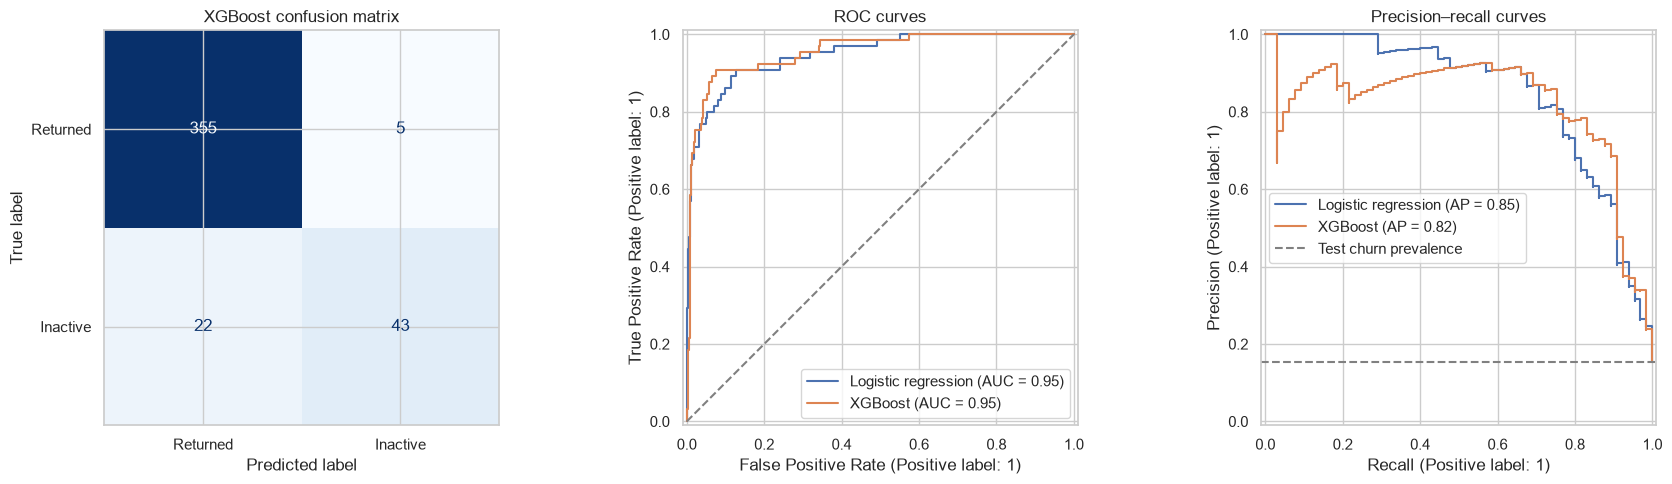

In [23]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    xgb_test_prediction,
    display_labels=["Returned", "Inactive"],
    cmap="Blues",
    colorbar=False,
    ax=axes[0],
)
axes[0].set_title("XGBoost confusion matrix")

for name in ["Logistic regression", "XGBoost"]:
    RocCurveDisplay.from_predictions(
        y_test,
        test_probabilities[name],
        name=name,
        ax=axes[1],
    )

    PrecisionRecallDisplay.from_predictions(
        y_test,
        test_probabilities[name],
        name=name,
        ax=axes[2],
    )

axes[1].plot([0, 1], [0, 1], "--", color="grey")
axes[1].set_title("ROC curves")

axes[2].axhline(
    y_test.mean(),
    linestyle="--",
    color="grey",
    label="Test churn prevalence",
)
axes[2].set_title("Precision–recall curves")
axes[2].legend()

plt.tight_layout()
plt.show()

## Evaluate Retention Prioritisation

In [24]:
CONTACT_FRACTION = 0.20

number_to_contact = max(
    1, int(np.ceil(len(y_test) * CONTACT_FRACTION))
)

ranked_positions = np.argsort(
    -xgb_test_probability, kind="stable"
)

selected_positions = ranked_positions[:number_to_contact]
selected_labels = y_test.iloc[selected_positions]

precision_at_budget = selected_labels.mean()
recall_at_budget = selected_labels.sum() / y_test.sum()
lift_at_budget = precision_at_budget / y_test.mean()

budget_results = pd.DataFrame([{
    "contact_fraction": CONTACT_FRACTION,
    "players_selected": number_to_contact,
    "actual_churners_selected": int(selected_labels.sum()),
    "precision_at_budget": precision_at_budget,
    "recall_at_budget": recall_at_budget,
    "lift_over_random": lift_at_budget,
}])

display(budget_results.round(4))

risk_table = pd.DataFrame({
    "user_id": X_test.index,
    "actual_churn": y_test.to_numpy(),
    "churn_score": xgb_test_probability,
    "predicted_churn": xgb_test_prediction,
}).sort_values("churn_score", ascending=False)

display(risk_table.head(10))

,contact_fraction,players_selected,actual_churners_selected,precision_at_budget,recall_at_budget,lift_over_random
0,0.2,85,58,0.6824,0.8923,4.4615


,user_id,actual_churn,churn_score,predicted_churn
276,2412,1,0.936546,1
254,2654,1,0.923119,1
123,1783,0,0.918215,1
128,1852,1,0.915353,1
141,1505,1,0.909442,1
31,3813,1,0.904687,1
231,2899,1,0.900265,1
296,1077,1,0.897376,1
319,1419,1,0.896268,1
420,1098,1,0.884340,1


## Calculate SHAP Explanations

In [25]:
background = X_train_xgb.sample(
    n=min(100, len(X_train_xgb)),
    random_state=SEED,
)

X_explain = X_test_xgb.sample(
    n=min(300, len(X_test_xgb)),
    random_state=SEED,
)

explainer = shap.TreeExplainer(
    xgb_model,
    data=background,
    feature_perturbation="interventional",
    model_output="probability",
)

shap_values = explainer(X_explain)

reconstructed_probability = (
    np.asarray(shap_values.base_values).reshape(-1)
    + shap_values.values.sum(axis=1)
)

np.testing.assert_allclose(
    reconstructed_probability,
    xgb_model.predict_proba(X_explain)[:, 1],
    atol=1e-5,
    rtol=1e-4,
)

print("SHAP explanations calculated and checked.")

SHAP explanations calculated and checked.


## Show Overall Feature Importance

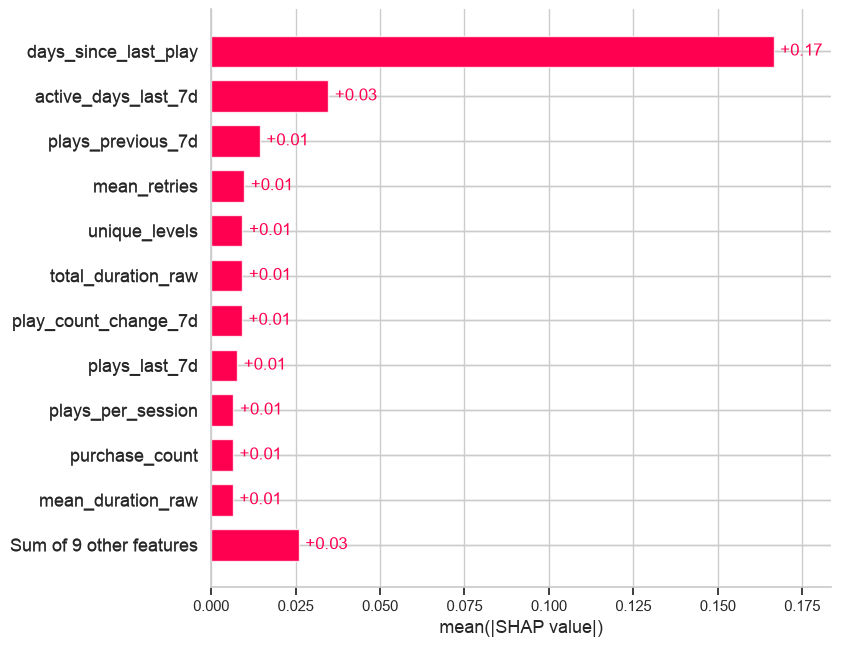

,feature,mean_absolute_shap
10,days_since_last_play,0.166506
14,active_days_last_7d,0.034638
13,plays_previous_7d,0.014368
7,mean_retries,0.009760
3,unique_levels,0.009263
9,total_duration_raw,0.009187
15,play_count_change_7d,0.009098
12,plays_last_7d,0.007673
11,plays_per_session,0.006551
16,purchase_count,0.006426


In [26]:
shap.plots.bar(shap_values, max_display=12)

shap_importance = (
    pd.DataFrame({
        "feature": X_explain.columns,
        "mean_absolute_shap": np.abs(
            shap_values.values
        ).mean(axis=0),
    })
    .sort_values("mean_absolute_shap", ascending=False)
)

display(shap_importance.head(12))

## Show the Direction of Feature Effects

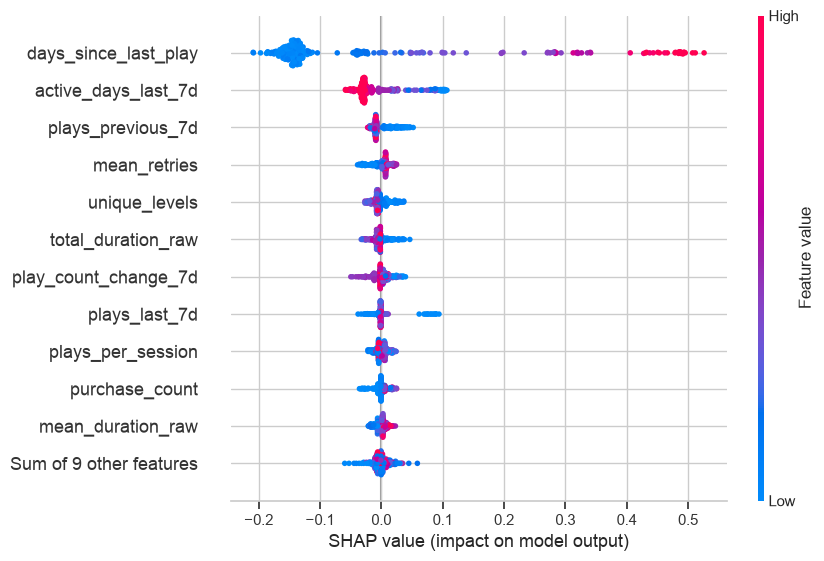

In [27]:
shap.plots.beeswarm(
    shap_values,
    max_display=12,
)

## Explain One High Risk Player

Player ID: 2654
Predicted churn score: 92.3%
Observed churn label: 1


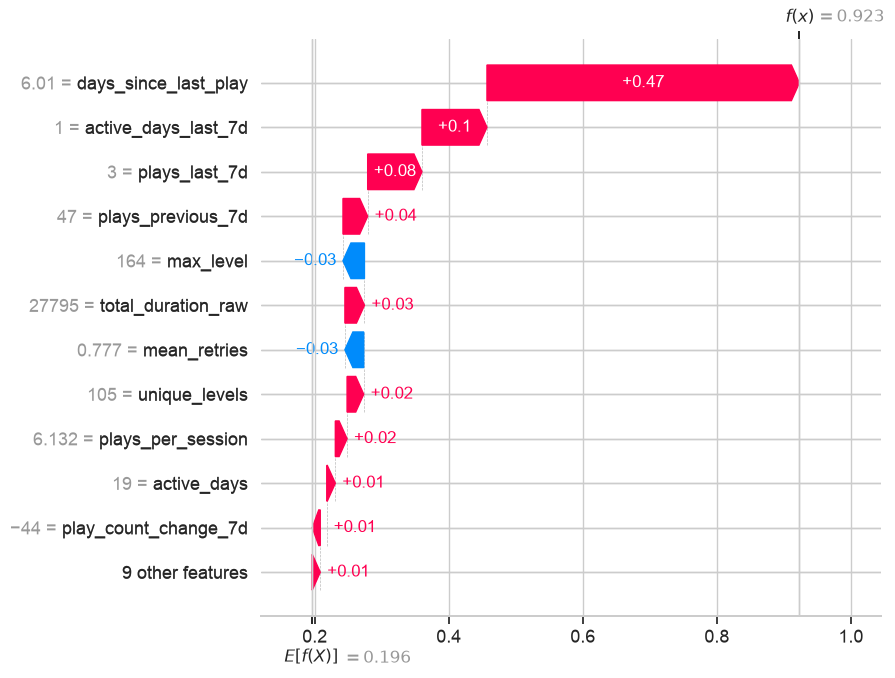

In [28]:
explanation_probabilities = xgb_model.predict_proba(
    X_explain
)[:, 1]

player_position = int(np.argmax(explanation_probabilities))
player_id = X_explain.index[player_position]

print("Player ID:", player_id)
print(
    "Predicted churn score:",
    f"{explanation_probabilities[player_position]:.1%}",
)
print("Observed churn label:", int(y_test.loc[player_id]))

shap.plots.waterfall(
    shap_values[player_position],
    max_display=12,
)

## Save Results and Model

In [29]:
OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

xgb_pipeline = Pipeline([
    ("imputer", xgb_imputer),
    ("classifier", xgb_model),
])

joblib.dump(
    {
        "pipeline": xgb_pipeline,
        "feature_columns": X_train.columns.tolist(),
        "threshold": thresholds["XGBoost"],
        "observation_days": OBSERVATION_DAYS,
        "prediction_days": PREDICTION_DAYS,
        "cohort": "Players active during the final observation week",
    },
    OUTPUT_DIR / "churn_model.joblib",
)

test_results.to_csv(
    OUTPUT_DIR / "test_metrics.csv", index=False
)
budget_results.to_csv(
    OUTPUT_DIR / "retention_targeting_metrics.csv", index=False
)
risk_table.to_csv(
    OUTPUT_DIR / "test_player_predictions.csv", index=False
)
shap_importance.to_csv(
    OUTPUT_DIR / "shap_feature_importance.csv", index=False
)

package_versions = {
    name: version(name)
    for name in [
        "pandas", "numpy", "matplotlib", "seaborn",
        "scikit-learn", "xgboost", "shap", "joblib",
    ]
}

metadata = {
    "seed": SEED,
    "dataset_end_assumption": str(DATA_END),
    "observation_days": OBSERVATION_DAYS,
    "prediction_days": PREDICTION_DAYS,
    "feature_columns": X_train.columns.tolist(),
    "xgboost_threshold": thresholds["XGBoost"],
    "versions": package_versions,
}

(OUTPUT_DIR / "run_metadata.json").write_text(
    json.dumps(metadata, indent=2),
    encoding="utf-8",
)

(OUTPUT_DIR / "requirements_recorded.txt").write_text(
    "\n".join(
        f"{name}=={installed_version}"
        for name, installed_version in package_versions.items()
    ),
    encoding="utf-8",
)

print("Saved results to:", OUTPUT_DIR.resolve())

Saved results to: /Users/adityaraj/Desktop/Churn/outputs


## Generate a Factual Results Summary

In [30]:
xgb_metrics = (
    test_results.set_index("model").loc["XGBoost"]
)

print("GAME PLAYER CHURN PROJECT")
print("-" * 40)
print(f"Modelled players: {len(model_data):,}")
print(f"Held-out test players: {len(y_test):,}")
print(f"Test churn prevalence: {y_test.mean():.1%}")
print(f"XGBoost ROC-AUC: {xgb_metrics['roc_auc']:.3f}")
print(
    f"XGBoost average precision: "
    f"{xgb_metrics['average_precision']:.3f}"
)
print(f"XGBoost F1: {xgb_metrics['f1']:.3f}")
print(
    f"Churners captured in highest-risk 20%: "
    f"{recall_at_budget:.1%}"
)
print(f"Lift over random targeting: {lift_at_budget:.2f}x")

print("\nLargest model contributors:")
for feature in shap_importance["feature"].head(5):
    print("-", feature)

print(
    "\nThese results measure prediction and prioritisation. "
    "They do not demonstrate reduced churn or increased revenue."
)

GAME PLAYER CHURN PROJECT
----------------------------------------
Modelled players: 2,124
Held-out test players: 425
Test churn prevalence: 15.3%
XGBoost ROC-AUC: 0.955
XGBoost average precision: 0.820
XGBoost F1: 0.761
Churners captured in highest-risk 20%: 89.2%
Lift over random targeting: 4.46x

Largest model contributors:
- days_since_last_play
- active_days_last_7d
- plays_previous_7d
- mean_retries
- unique_levels

These results measure prediction and prioritisation. They do not demonstrate reduced churn or increased revenue.
